# Support Vector Machines Exercises


**NOTICE:**
1. You are allowed to work in groups of up to three people but **have to document** your group's\
 members in the top cell of your notebook.
2. **Comment your code**, explain what you do (refer to the slides). It will help you understand the topics\
 and help me understand your thinking progress. Quality of comments will be graded.
3. **Discuss** and analyze your results, **write-down your learnings**. These exercises are no programming\
 exercises it is about learning and getting a touch for these methods. Such questions might be asked in the\
 final exams.
4. Feel free to **experiment** with these methods. Change parameters think about improvements, write down\
 what you learned. This is not only about collecting points for the final grade, it is about understanding\
  the methods.
5. All exercises can be part of the final exam, your **answers, experiments and documented learnings will be graded**.

In [1]:
# Install qsolvers and gurobi solver
#
!pip install qpsolvers
!pip install -i https://pypi.gurobi.com gurobipy

# Download data
#
!wget https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/baseball.pickle -P ../data

Looking in indexes: https://pypi.gurobi.com
ERROR: Could not find a version that satisfies the requirement gurobipy (from versions: none)
ERROR: No matching distribution found for gurobipy
--2026-11-17 09:35:11--  https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/baseball.pickle
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/shegenbart/Jupyter-Exercises/main/data/baseball.pickle [following]
--2026-11-17 09:35:12--  https://raw.githubusercontent.com/shegenbart/Jupyter-Exercises/main/data/baseball.pickle
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 177444 (173K) [application/oc

In [2]:
#Imports, Helper Functions and Data Structures
#

import numpy as np
from qpsolvers import solve_qp
import numpy as np
import pickle

from dataclasses import dataclass
def load_dataset(filename):
    with open(filename, 'rb') as fd:
        dataset = pickle.load(fd)
    return dataset

# Baseball dataset
#
@dataclass
class Dataset:
    Description: str
    Attributes: list()
    Targets: list()
    X: np.array
    Y: np.array


# Helper functions needed for exercise
#
def plot_hyperplane(X,Y, n, b):
    """Plots the hyperplane defined by normalvector n and bias b.

    Parameters
    ----------
    X: np.array
        A two-dimensonal numpy array containing features.
    Y: np.array
        A one dimensional numpy array containing class labels. Class labels
        are assumed not to be one-hot encoded but categorical integer values.
    n: np.array
        A two-dimensional normalvector.
    b: float
        Bias of the hyperplane.

    Returns
    ----------
    Nothing
    """

    fig = plt.figure(figsize=(10,5))
    plt.scatter(X[Y == 1, 0], X[Y == 1, 1])
    plt.scatter(X[Y == -1, 0], X[Y == -1, 1])

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = (np.dot(xy, n) - b).reshape(XX.shape)
    cs = ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    plt.clabel(cs, inline=1)
    plt.grid(True)


def gen_data(npoints=10, linear_separable=True):

    assert npoints >= 4, 'Requires at least 4 points. '

    # Generate a random normal-vector
    #
    n = np.random.randn(2)
    n = n / np.linalg.norm(n)

    # Generate a random bias
    #
    b = np.random.randn(1)

    # Generate random points and label them such that they are linearly separable
    #
    X = np.random.randn(npoints,2) * 5

    tmp = np.dot(X, n) - b > 0
    Y = np.zeros(tmp.shape)
    Y[tmp == True] = 1
    Y[tmp == False] = -1

    if linear_separable == False:
        np.random.shuffle(Y)

    fig = plt.figure(figsize=(10,5))
    plt.scatter(X[Y == 1,0], X[Y == 1,1])
    plt.scatter(X[Y == -1,0], X[Y == -1,1])
    plt.grid(True)

    return X,Y

import numpy as np
import matplotlib.pyplot as plt

def plot_svm(X,Y, clf):

    fig = plt.figure(figsize=(10,5))
    plt.scatter(X[Y == 1, 0], X[Y == 1, 1])
    plt.scatter(X[Y == -1, 0], X[Y == -1, 1])

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = clf.decision_function(xy).reshape(XX.shape)
    cs = ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    plt.clabel(cs, inline=1)
    plt.grid(True)

### Exercises (Optional): SVM Hard-Margin

Remember: We formulated the search for the best hyperplane as an optimization problem of the form

$$\begin{equation*}
\begin{aligned}
& \underset{n}{\text{minimize}}
& & \|n\| = \sum_i n_i^2 \\
& \text{subject to}
& &y_i (n \cdot x_i -b) \geq 1, \quad \forall i.
\end{aligned}
\end{equation*}$$


We have a quadratic objective function and linear constraints. Problems of this sort are known as quadratic programs (QP).

Quadratic programs are defined as
$$\begin{equation*}
\begin{aligned}
& \underset{x}{\text{minimize}}
& & \frac{1}{2} x^T P x + q^Tx \\
& \text{subject to}
& & Gx \leq h \\
& & & A x = b \\
& & & lb \leq x \leq ub
\end{aligned}
\end{equation*}$$

We use a QP solver to find our solution given a set of linear equality constraints and a set of linear inequality constraints. In our example, there are only inequality constraints and an objective function, we therefore have to **define** $P$, $q$, $G$ and $h$.

In this example we assume our points are 2-dimensional. Therefore the normalvector of our plane is only 2-dimensional $n=(n_x, n_y)^T$.




### Exercise 1 (Optional):
We start by defining our objective function in the form $\frac{1}{2} x^T P x + q^Tx$ where $x$ is a vector of our variables $(n_x, n_y, b)$, $P$ is a quadratic cost-matrix and $q$ is a cost-vector.

Find a 3x3-matrix $P$ and a 1x3-vector $q$ such that:

$(n_x, n_y, b)\; P\; (n_x, n_y, b)^T + q\; (n_x, n_y, b)^T= n_x^2 + n_y^2$

*This exercise is best solved using pen and paper. Write your solution down here for later reference.*

### Exercise 2 (Optional):


We next have to convert our constraints from $\geq$ to $\leq$. We do this by multiplying the inequality with $-1$

$$y_i (n \cdot x_i -b) \geq 1 = -y_i (n \cdot x_i -b) \leq -1$$

For a given set of two points $x_1 = (x_{11}, x_{12}) = (3,2),\, x_2 = (x_{21},x_{22}) = (-3,4)$ with labels $y_1 = 1, y_2 = -1$
Find the matrix $G$ such that

$G\; (n_x, n_y, b)^T = \begin{pmatrix}
-y_1( n\cdot x_1 -b)\\
-y_2( n\cdot x_2 -b)
\end{pmatrix} = \begin{pmatrix}
-y_1( n_x x_{11}  + n_y x_{12} -b)\\
-y_2( n_x x_{21}  + n_y x_{22} -b)
\end{pmatrix} = \begin{pmatrix}
-3n_x  - 2n_y + b\\
-3n_x  + 4n_y  -b
\end{pmatrix}$


*This exercise is best solved using pen and paper. Write your solution down here for later reference.*

### Exercise 3 (Optional):

Manually define $P$, $q$, $G$ and $h$ using appropriate numpy-arrays to solve the optimization problem with ```solve_qp(P,q,G,h)```. Then plot your results using the ```plot_hyperplane()``` function.

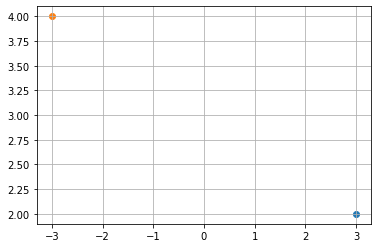

In [ ]:
# Generates and plots the training data
#
X = np.array([[3, 2], [-3, 4]])
Y = np.array([1, -1])


import matplotlib.pyplot as plt
plt.scatter(X[Y == 1,0], X[Y == 1,1])
plt.scatter(X[Y == -1,0], X[Y == -1,1])
plt.grid(True)


### Exercise 4 (Optional):

We saw that $P$ and $q$ do not depend on our training-data. But $G$ and $h$ does depend on our training-data.
* Implement a function that creates a matrix $G$ and vector $h$ based on a given set of training features $X$ and labels $Y$.
* Use the ```gen_data()```function to generate data and use your implementation to find a hyperplane via ```solve_qp(P,q,G,h)``` and plot it.
* Generate some non-linearly separable data using ```gen_data(linear_separable=False)```and try to find a hyperplane using the ```solve_qp(P,q,G,h)``` function, what happens and why?

## Exercises (Mandatory)

Let us now use the implementation of SVM from scikit-learn.

### Exercise 1: Linear SVM in scikit-learn

**Summary:** In this exercise you will use scikit-learn to train a support vector machine. You will experiment with the trained classifier and learn   
how to connect it to the theoretic knowledge provided in the lecture.  

**Provided Code:** The ```gen_data()``` method implemented in a cell above can be used to generate training/test data.    
The ```plot_svm(X,Y,clf)``` can be used to plot the decision boundary of the SVM.

**Your Tasks in this exercise:**
1. Generate training data using ```X,Y = gen_data()```.
2. Train a linear support vector machine using scikit-learn.
3. Plot your decision boundary using the ```plot_svm(X,Y,clf)``` function.
4. Have a look at the decision boundary (you can find the values of the normal vectors and bias term using clf.coef_[0] and clf.intercept_). What does it tell you?
* If you did the Hard-Margin SVM Exercises:
    * Compare the decision boundary found by scikit-learn to the decision boundary you would find using your **Hard-Margin SVM** from the previous exercise using the same training data.
    * Compare the values of the normal vectors and bias term (clf.coef_[0] and clf.intercept_) to your **Hard-Margin** solution.
5. Document your learnings.



w = [ 0.41745489 -0.4807748 ]
b = -3.2674205480849006
Margin-Breite = 3.1410956683613924
Support Vectors:
 [[ 2.18211994 -2.82145376]
 [ 4.24152566 -5.1932319 ]]


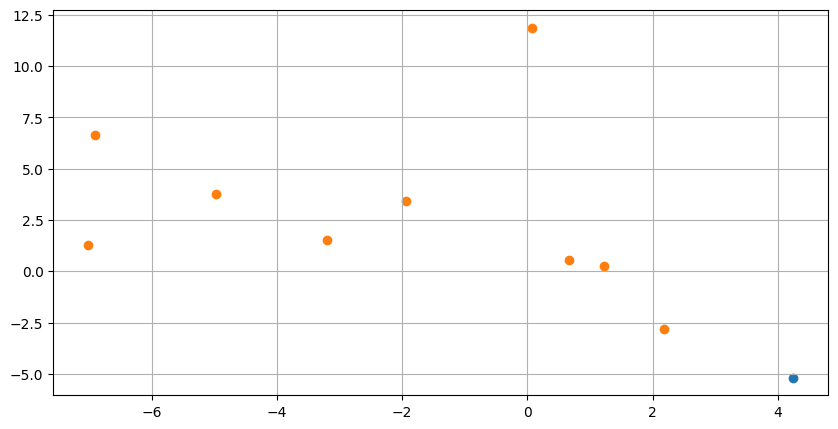

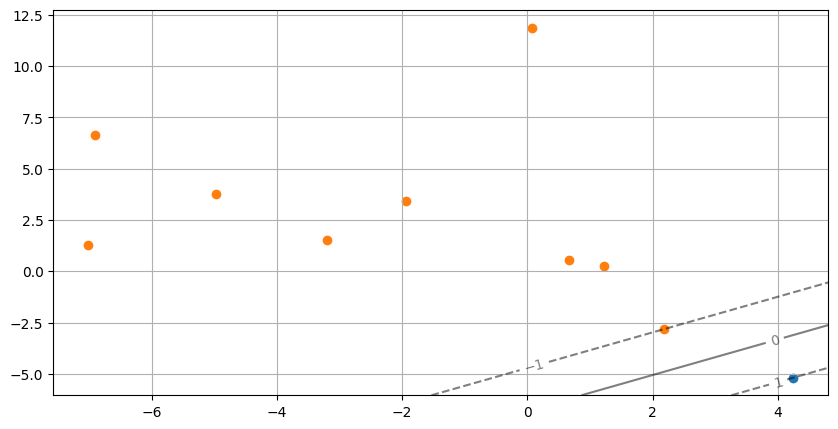

In [4]:
from sklearn.svm import SVC

X,Y = gen_data()

clf = SVC(kernel='linear')
clf.fit(X, Y)

plot_svm(X,Y,clf)

w = clf.coef_[0]
b = clf.intercept_[0]
print("w =", w)
print("b =", b)
print("Margin-Breite =", 2 / np.linalg.norm(w))
print("Support Vectors:\n", clf.support_vectors_)


### Exercise 2: Kernel Trick

**Summary:** Compute the centroid of a list of points.

**Provided Code:** The ```gen_data()``` method implemented in a cell above can be used to generate training/test data.    
The ```plot_svm(X,Y,clf)``` can be used to plot the decision boundary of the SVM.

**Your Tasks in this exercise:**
1. Generate data using ```X,Y = gen_data(linear_separable=False)```.
2. Train a linear support vector machine using scikit-learn.
3. Plot your decision boundary using the ```plot_svm(X,Y,clf)``` function.
4. Train another suppor vector machine using the kernel trick in scikit-learn.
5. Plot your decision boundary of the non-linear svm using the ```plot_svm(X,Y,clf)``` function. How does the decision boundary change? What could possibly happen?
6. Document your learnings.






Accuracy linear: 0.8
Accuracy RBF: 0.9


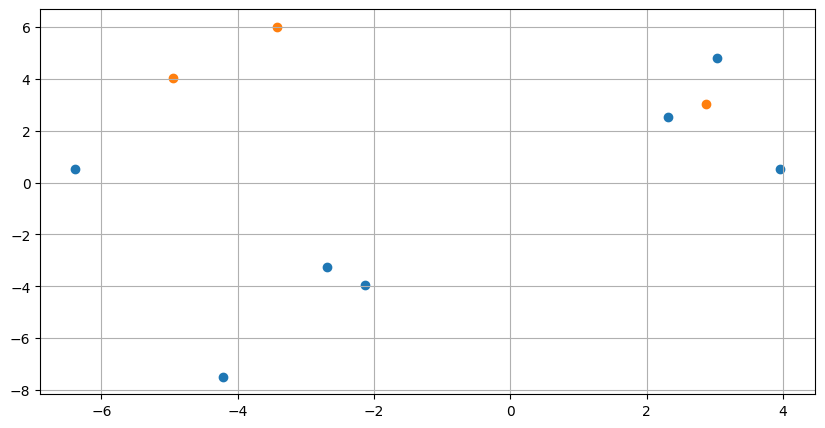

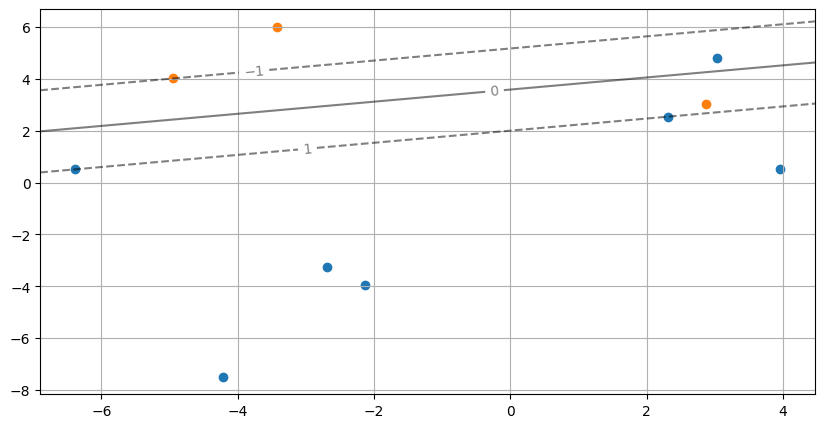

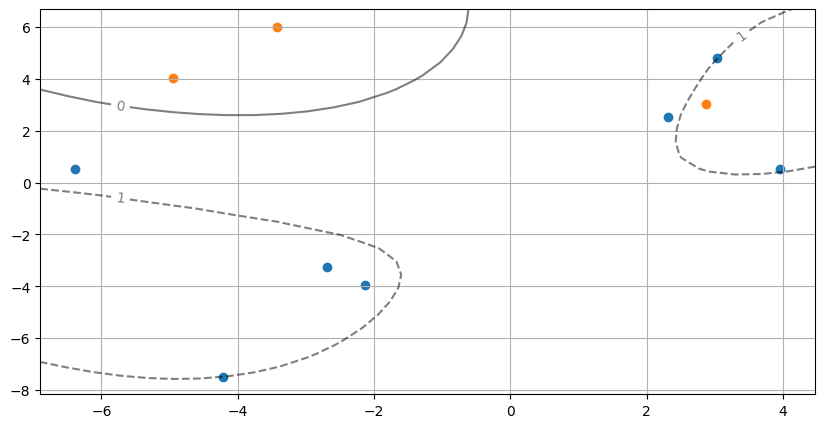

In [6]:
from sklearn.svm import SVC

X, Y = gen_data(linear_separable=False)

clf_lin = SVC(kernel='linear')
clf_lin.fit(X, Y)
plot_svm(X, Y, clf_lin)
print("Accuracy linear:", clf_lin.score(X, Y))

clf_rbf = SVC(kernel='rbf')
clf_rbf.fit(X, Y)
plot_svm(X, Y, clf_rbf)
print("Accuracy RBF:", clf_rbf.score(X, Y))


## Exercise 3: Classify the Baseball Dataset


**Summary:** Compute the centroid of a list of points.

**Provided Code:** Use the ```load_dataset(../data/baseball.pickle)``` method to load the baseball dataset.

**Your Tasks in this exercise:**
1. Load the baseball dataset using ```load_dataset(../data/baseball.pickle)```.
2. Have a look at the dataset, there are multiple fields such as Attributes, Targets, Description, ...
3. Train a support vector machine that predicts wether a player will end up in the hall-of-fame or not (you can use the ```accuracy_score()``` method from sklearn to easily do this.
4. Compare a linear and a non-linear SVM, what is better, why?
5. Document your learnings.


**Hints:**
Do not train and test on the same set of data, this will result in too high accuracy. Instead use cross validation such as:

```python
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(baseball.X, baseball.Y)
```

Then train on ```X_train, Y_train``` and predict using ```X_test and Y_test```.


